# Telugu + English Handwritten Text OCR

Give it an image, get text back. Three engines are included so you can compare:

| Engine | Telugu | English | Handwriting quality | Cost |
|---|---|---|---|---|
| **EasyOCR** (default) | yes | yes | decent on neat writing | free, offline |
| **Tesseract** (optional) | yes (`tel`) | yes | weak on handwriting | free, offline |
| **Claude vision** (optional) | yes | yes | best on messy/cursive Telugu | paid API key |

**Pipeline:** load image -> preprocess (upscale, denoise, contrast) -> OCR -> group into lines -> visualize -> save to `.txt` / `.json`.

Works in Jupyter, VS Code, or Google Colab (a GPU speeds up EasyOCR but is not required).

## 1. Install dependencies

In [ ]:
# Run once. Restart the kernel afterwards if imports fail.
# !pip install -q easyocr opencv-python-headless pillow matplotlib numpy anthropic

# OPTIONAL Tesseract engine (Linux/Colab). Uncomment to use:
# !apt-get install -y -q tesseract-ocr tesseract-ocr-tel tesseract-ocr-eng
# !pip install -q pytesseract

Could not import runpy._run_module_as_main
Traceback (most recent call last):
  File "<frozen importlib._bootstrap>", line 1371, in _find_and_load
  File "<frozen importlib._bootstrap>", line 1342, in _find_and_load_unlocked
  File "<frozen importlib._bootstrap>", line 938, in _load_unlocked
  File "<frozen importlib._bootstrap>", line 1179, in exec_module
  File "<frozen runpy>", line 14, in <module>
  File "C:\Users\Acer\AppData\Roaming\uv\python\cpython-3.12-windows-x86_64-none\Lib\importlib\__init__.py", line 57, in <module>
    import warnings
  File "C:\Users\Acer\AppData\Roaming\uv\python\cpython-3.12-windows-x86_64-none\Lib\warnings.py", line 591, in <module>
    filterwarnings("default", category=DeprecationWarning,
  File "C:\Users\Acer\AppData\Roaming\uv\python\cpython-3.12-windows-x86_64-none\Lib\warnings.py", line 155, in filterwarnings
    import re
  File "C:\Users\Acer\AppData\Roaming\uv\python\cpython-3.12-windows-x86_64-none\Lib\re\__init__.py", line 125, in <module>


## 2. Configuration and image input

In [10]:
os.chdir(r'C:\Users\Acer\Desktop\MyProjects\Websites\Proj_Trikuta_OCR')
os.getcwd()

'C:\\Users\\Acer\\Desktop\\MyProjects\\Websites\\Proj_Trikuta_OCR'

Loaded C:\Users\Acer\Desktop\MyProjects\Websites\Proj_Trikuta_OCR\sample_img.jpeg shape = (866, 1265, 3)


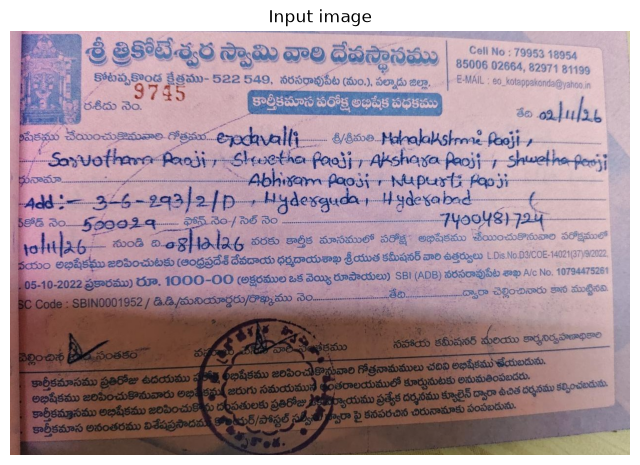

In [18]:
import os, json, base64, mimetypes
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ---------- settings ----------
IMAGE_PATH = r'C:\Users\Acer\Desktop\MyProjects\Websites\Proj_Trikuta_OCR\sample_img.jpeg'   
LANGS = ['te', 'en']             # Telugu + English
USE_GPU = False                  # True if you have CUDA
OUTPUT_PREFIX = 'ocr_result'     # outputs: ocr_result.txt / ocr_result.json
# ------------------------------

IMG_EXTS = {'.jpg', '.jpeg', '.png', '.webp', '.bmp', '.tif', '.tiff'}

def resolve_image(path):
    p = Path(path).expanduser()
    if p.is_file():
        return p.resolve()
    hits = [h for h in Path.cwd().rglob(p.name) if h.is_file()]
    if hits:
        print('Found at:', hits[0])
        return hits[0].resolve()
    here = [f.name for f in Path.cwd().iterdir() if f.suffix.lower() in IMG_EXTS]
    raise FileNotFoundError(
        f"Image '{path}' not found.\n"
        f"Notebook working directory: {Path.cwd()}\n"
        f"Image files in that folder: {here or 'none'}\n"
        f"Fix: set IMAGE_PATH to the full path of your image.")

def load_image(path):
    data = np.fromfile(str(path), dtype=np.uint8)      # works with Windows/non-ASCII paths
    img = cv2.imdecode(data, cv2.IMREAD_COLOR)
    if img is None:
        from PIL import Image
        img = cv2.cvtColor(np.array(Image.open(path).convert('RGB')), cv2.COLOR_RGB2BGR)
    return img

IMAGE_PATH = str(resolve_image(IMAGE_PATH))
img_bgr = load_image(IMAGE_PATH)
print('Loaded', IMAGE_PATH, 'shape =', img_bgr.shape)
plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
plt.axis('off'); plt.title('Input image'); plt.show()

In [19]:
# import os, json, base64, mimetypes
# import cv2
# import numpy as np
# import matplotlib.pyplot as plt

# # ---------- settings ----------
# IMAGE_PATH = 'sample_img.jpg'      # <- change to your image (jpg/png/webp)
# LANGS = ['te', 'en']           # Telugu + English
# USE_GPU = False                # True if you have CUDA
# OUTPUT_PREFIX = 'ocr_result'   # output files: ocr_result.txt / ocr_result.json
# # ------------------------------

# # Google Colab convenience: upload an image from your computer
# try:
#     from google.colab import files
#     if not os.path.exists(IMAGE_PATH):
#         up = files.upload()
#         IMAGE_PATH = list(up.keys())[0]
# except ImportError:
#     pass

# img_bgr = cv2.imread(IMAGE_PATH)

# assert img_bgr is not None, f'Could not read image: {IMAGE_PATH}'
# print('Loaded', IMAGE_PATH, 'shape =', img_bgr.shape)
# plt.figure(figsize=(8, 8))
# plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
# plt.axis('off'); plt.title('Input image'); plt.show()

## 3. Preprocessing

Upscaling small images, denoising and local contrast enhancement noticeably help handwriting. Binarization is optional because deep-learning OCR usually prefers grayscale.

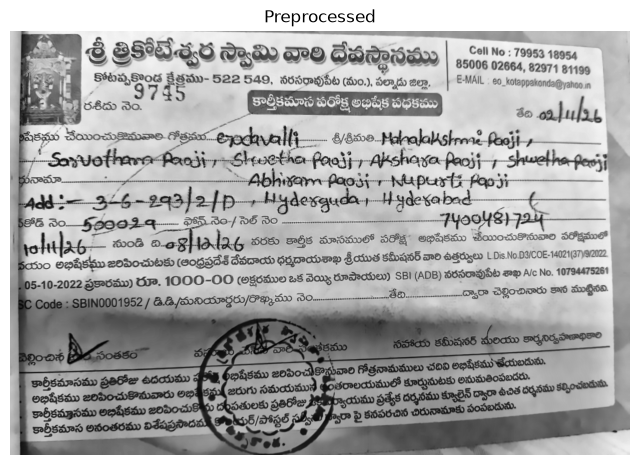

In [22]:
def preprocess(img, target_long_side=1800, binarize=False):
    h, w = img.shape[:2]
    long_side = max(h, w)
    if long_side < target_long_side:                     # upscale small images
        s = target_long_side / long_side
        img = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_CUBIC)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.fastNlMeansDenoising(gray, None, h=10, templateWindowSize=7, searchWindowSize=21)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    gray = clahe.apply(gray)
    if binarize:
        gray = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                     cv2.THRESH_BINARY, 31, 15)
    return gray

proc = preprocess(img_bgr, binarize=False)
plt.figure(figsize=(8, 8)); plt.imshow(proc, cmap='gray'); plt.axis('off')
plt.title('Preprocessed'); plt.show()

## 4. Engine A: EasyOCR (Telugu + English, offline)
The first run downloads the Telugu and English models (~100 MB).

In [23]:
import easyocr
reader = easyocr.Reader(LANGS, gpu=USE_GPU)   # first run downloads models (~100 MB)

def group_lines(results):
    """Merge word boxes into reading-order lines."""
    if not results:
        return []
    items = []
    for bbox, text, conf in results:
        xs = [p[0] for p in bbox]; ys = [p[1] for p in bbox]
        items.append(dict(x=min(xs), yc=sum(ys) / 4, h=max(ys) - min(ys), text=text, conf=conf))
    med_h = float(np.median([i['h'] for i in items]))
    items.sort(key=lambda i: i['yc'])
    lines = [[items[0]]]
    for it in items[1:]:
        line_y = np.mean([w['yc'] for w in lines[-1]])
        if abs(it['yc'] - line_y) < 0.6 * med_h:
            lines[-1].append(it)
        else:
            lines.append([it])
    return [' '.join(w['text'] for w in sorted(l, key=lambda w: w['x'])) for l in lines]

def run_easyocr(gray_img):
    results = reader.readtext(
        gray_img, detail=1, paragraph=False,
        text_threshold=0.5, low_text=0.3, link_threshold=0.4,
        width_ths=0.7, mag_ratio=1.5, decoder='beamsearch', beamWidth=5)
    return results, group_lines(results)

easy_results, easy_lines = run_easyocr(proc)
easy_text = '\n'.join(easy_lines)
print('===== EasyOCR output =====')
print(easy_text)
if easy_results:
    print('\nMean confidence: %.2f' % np.mean([c for _, _, c in easy_results]))

Using CPU. Note: This module is much faster with a GPU.


Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete

c:\Users\Acer\Desktop\Agentic AI\1. Langchain\Langchain By Krish\.venv\Lib\site-packages\torch\ao\nn\quantized\dynamic\modules\rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\quantized\Quantizer.cpp:116.)
  w_ih = torch.quantize_per_tensor(
c:\Users\Acer\Desktop\Agentic AI\1. Langchain\Langchain By Krish\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
c:\Users\Acer\Desktop\Agentic AI\1. Langchain\Langchain By Krish\.venv\Lib\site-packages\easyocr\utils.py:249

===== EasyOCR output =====
శ్రీత్రికోటేశ్వర స్వామివారి దేవస్థానము Cel No : 79953 18954
కోటప్పక [కొండక్ేత్రము- 522 549,  నరసరావుపేట (మం:), పల్నాడు జిల్లా; 85006 02664, 82971 81199 E-MAIL 00 _ kolappakonda@rahoo in
రశీదు నెం: కార్తీకమాస 'పరోక్షల అభిషేక పధకము తేది 02[1/3'
రిషేకము చేయించ కద eocavallt శ్రీశ్రీమతి FakalalSrrmag poji
SoJotla^ Paot 91" "Skectha-FaeJiv AShote-గoji ? Saelaterji
రునామా Abntam Qoost ా wupurrt Popsi
4d:- 3-273/2/p ddetgton Wudcuabng
5కోడ్ నెం_59993 ? ఫోన్ నెం / సెల్ నెం 7toot8/79t
loltప నుండి దిం8  a~ వరకు కార్తీక మాసములో పరోక్ష   అభిషేకము చేయించ
నయం 05-10-2022 ప్రకారము రూ: అభిషేకము జరిపించుటకు (ఆంధ్రప్రదేశదేవదాయ ధర్మదాయశాఖ శ్రీయుత కమీషనర్వార 1000-00 (లక్షరముల ఒక వెయ్యి ' రూపాయలు) SBI (ADB) నరసరావుపేట శాఖ Ac No: 1079
SC Code : SBIN0001952 / డిడి మనియార్డరు/ర ఖ్క ము నెం తేది 0ా చెల్లించినారు కాన ముట్టినవి
చెల్లించిన సంతకం 0 తరము సహాయ కమీషనర్ మరియు కార్ష్యనిర్వహణాధికాలి
కార్తీకమాసము ప్రతిరోజు ఉదయము @భిషేకుముమరిమునక ంతరాలయములో కూర్జునుటకు లనుమతింపబితరుర వారి గోత్రనామమ

### Visualize detected text regions
(Boxes only, no text labels, because matplotlib's default font cannot render Telugu.)

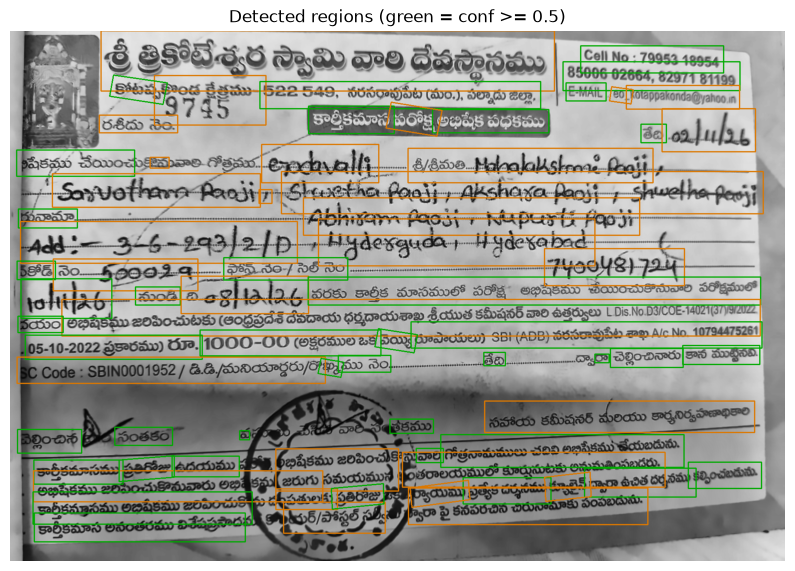

In [24]:
vis = cv2.cvtColor(proc, cv2.COLOR_GRAY2RGB)
for bbox, text, conf in easy_results:
    pts = np.array(bbox, dtype=np.int32)
    color = (0, 170, 0) if conf >= 0.5 else (220, 120, 0)   # green = confident, orange = shaky
    cv2.polylines(vis, [pts], True, color, 2)
plt.figure(figsize=(10, 10)); plt.imshow(vis); plt.axis('off')
plt.title('Detected regions (green = conf >= 0.5)'); plt.show()

## 5. Engine B: Tesseract (optional)
Fast, but generally poor on handwriting. Useful for printed Telugu. Requires the apt/pip install lines in step 1.

In [ ]:
def run_tesseract(gray_img):
    import pytesseract
    return pytesseract.image_to_string(gray_img, lang='tel+eng', config='--oem 1 --psm 6')

RUN_TESSERACT = False   # set True after installing Tesseract
tess_text = ''
if RUN_TESSERACT:
    tess_text = run_tesseract(proc)
    print('===== Tesseract output =====')
    print(tess_text)

## 6. Engine C: Claude vision (optional, best for messy Telugu handwriting)

Sends the original image to Claude and asks for a faithful transcription. Needs an API key from console.anthropic.com (usage is billed). The image is sent to Anthropic's API, so skip this for confidential documents.

In [25]:
import getpass, anthropic

CLAUDE_MODEL = 'claude-sonnet-5-5'
PROMPT = (
    'Transcribe all handwritten and printed text in this image exactly as written. '
    'The text may be Telugu, English, or a mix. Keep Telugu in Telugu script and English in English; '
    'do not translate or transliterate. Preserve line breaks and reading order. '
    'If a word is illegible, write [illegible]. Output only the transcription.'
)

def run_claude(path):
    key = os.environ.get('ANTHROPIC_API_KEY') or getpass.getpass('Anthropic API key: ')
    client = anthropic.Anthropic(api_key=key)
    media_type = mimetypes.guess_type(path)[0] or 'image/jpeg'
    with open(path, 'rb') as f:
        data = base64.standard_b64encode(f.read()).decode()
    msg = client.messages.create(
        model=CLAUDE_MODEL, max_tokens=4000,
        messages=[{'role': 'user', 'content': [
            {'type': 'image', 'source': {'type': 'base64', 'media_type': media_type, 'data': data}},
            {'type': 'text', 'text': PROMPT}]}])
    return msg.content[0].text

RUN_CLAUDE = False    # set True to use it
claude_text = ''
if RUN_CLAUDE:
    claude_text = run_claude(IMAGE_PATH)
    print('===== Claude output =====')
    print(claude_text)

KeyboardInterrupt: 

## 7. Save results

In [ ]:
# Pick the best available output as the final text
final_text = claude_text or easy_text or tess_text

with open(OUTPUT_PREFIX + '.txt', 'w', encoding='utf-8') as f:
    f.write(final_text)

report = {
    'image': IMAGE_PATH,
    'easyocr_text': easy_text,
    'easyocr_words': [{'text': t, 'confidence': float(c), 'bbox': [[float(x), float(y)] for x, y in b]}
                      for b, t, c in easy_results],
    'tesseract_text': tess_text,
    'claude_text': claude_text,
}
with open(OUTPUT_PREFIX + '.json', 'w', encoding='utf-8') as f:
    json.dump(report, f, ensure_ascii=False, indent=2)   # ensure_ascii=False keeps Telugu readable

print('Saved:', OUTPUT_PREFIX + '.txt', 'and', OUTPUT_PREFIX + '.json')

## Tips for better accuracy

- **Photo quality matters most:** good light, no shadows, camera parallel to the page, dark pen on plain paper.
- If EasyOCR merges or splits words badly, tweak `width_ths` (0.5 to 1.0) and `mag_ratio` (1.0 to 2.5) in `run_easyocr`.
- Try `preprocess(..., binarize=True)` on faint pencil writing or uneven lighting.
- Very cursive Telugu is hard for any offline model. For that, use Engine C, or fine-tune a model (e.g. TrOCR or PaddleOCR with Telugu data) on your own labeled handwriting samples.
- Low-confidence words (orange boxes) are the ones worth proofreading by hand.